# Paket B — Renk yöntemi ve filtre (5. adım), D2
Önce **yalnız G-1…G-8** ile eşikler belirlenir, `freeze_params()` ile dondurulur (Dondurma 2; params.json'un kopyası
otomatik olarak `kayitlar/` altına alınır). Kontrol görüntüleri bundan önce çalıştırılamaz (kod engeller).

> Colab: defteri Drive'da açın (çift tık → *Birlikte aç → Google Colaboratory*). İlk hücre Drive'ı bağlar ve proje klasörünü kendisi bulur. Defterde yaptığınız değişiklik doğrudan Drive'daki dosyaya kaydedilir; *Drive'a kopya kaydet* **kullanmayın** (kopya "Colab Notebooks" klasörüne gider, grup göremez).

In [15]:
# --- Kurulum: Google Drive'ı bağlar ve proje klasörünü bulur (GitHub gerekmez) ---
PROJE = ''   # boş bırakın, otomatik bulunur; bulunamazsa Drive'daki yolu yazın: '/content/drive/MyDrive/.../yelek-tespiti'
import os, sys, glob, unicodedata
sys.dont_write_bytecode = True                      # Drive'daki src/ klasörüne __pycache__ yazılmasın

def _proje_mi(p):
    return os.path.isfile(os.path.join(p, 'src', 'common.py')) and os.path.isfile(os.path.join(p, 'config', 'params.json'))

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJE = PROJE.strip().rstrip('/')
    if PROJE and not _proje_mi(PROJE):               # Türkçe harf kodlaması farkı (ör. 'Ödevler')
        PROJE = next((unicodedata.normalize(f, PROJE) for f in ('NFC', 'NFD')
                      if _proje_mi(unicodedata.normalize(f, PROJE))), PROJE)
    if not PROJE:                                    # Drive'ım ve ortak drive'larda 4 klasör derinliğe kadar ara
        for d in range(5):
            bulunan = sorted({os.path.dirname(os.path.dirname(p))
                              for k in ('/content/drive/MyDrive', '/content/drive/Shareddrives')
                              for p in glob.glob(os.path.join(k, *['*'] * d, 'src', 'common.py'))})
            bulunan = [p for p in bulunan if _proje_mi(p)]
            if bulunan:
                PROJE = bulunan[0]
                if len(bulunan) > 1:
                    print('Birden fazla proje klasörü bulundu, ilki kullanılıyor:', *bulunan, sep='\n  ')
                break
    if not PROJE or not _proje_mi(PROJE):
        raise FileNotFoundError("Proje klasörü bulunamadı. Drive'da paylaşılan 'yelek-tespiti' klasörüne sağ tık -> "
                                "Düzenle -> Kısayol ekle -> Drive'ım; sonra bu hücreyi yeniden çalıştırın "
                                "(ya da yukarıda PROJE = '/content/drive/MyDrive/...' yazın).")
    os.chdir(PROJE)
elif os.path.basename(os.getcwd()) == 'notebooks':  # Colab dışında (Jupyter / VS Code)
    os.chdir('..')
sys.path.insert(0, os.path.join(os.getcwd(), 'src'))
try:                                                # Colab'ın Python 3.13 sürümünde autoreload bozuk; varsa açılır, yoksa geçilir
    get_ipython().run_line_magic('reload_ext', 'autoreload'); get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass
import warnings; warnings.filterwarnings('ignore')
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # defter boyutu küçük kalsın
from common import *
gt, P = load_gt(), load_params()
durum()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proje klasörü : /content/drive/MyDrive/Yelek tespit deneme/yelek-tespiti-drive/yelek-tespiti
Görüntüler    : 20/20 hazır (data/images_1024)
gt.json       : 20 görüntü, 20 tanesinde kutu var
params dondu mu: True 2026-11-10T21:09:21
Kayıtlar      : 1 dosya kaydı, son: dondurma-2 (2026-11-10T21:09:21)


,id,bolge,n_px,H_p5,H_p50,H_p95,S_p5,S_p50,V_p5,V_p50
0,G-1,yelek,13117,11.0,27.0,30.0,82.0,100.0,108.0,224.0
1,G-1,arka_plan,24022,4.0,10.0,15.0,81.0,96.0,85.0,132.0
2,G-2,yelek,23839,5.0,14.0,19.0,95.0,195.0,112.0,236.0
3,G-2,arka_plan,58089,0.0,103.0,179.0,82.0,154.0,84.0,113.0
4,G-3,yelek,13630,18.0,35.0,39.0,92.0,160.0,103.0,177.0
5,G-3,arka_plan,30202,5.0,15.0,39.0,81.0,113.0,83.0,128.0
6,G-4,yeleksiz_govde,25321,105.0,116.0,119.0,82.0,98.0,85.0,124.0
7,G-4,arka_plan,400963,20.0,106.0,110.0,83.0,116.0,125.0,221.0
8,G-5,yeleksiz_govde,249580,8.0,177.0,178.0,95.0,205.0,153.0,214.0
9,G-5,arka_plan,53452,5.0,11.0,27.0,82.0,132.0,130.0,222.0


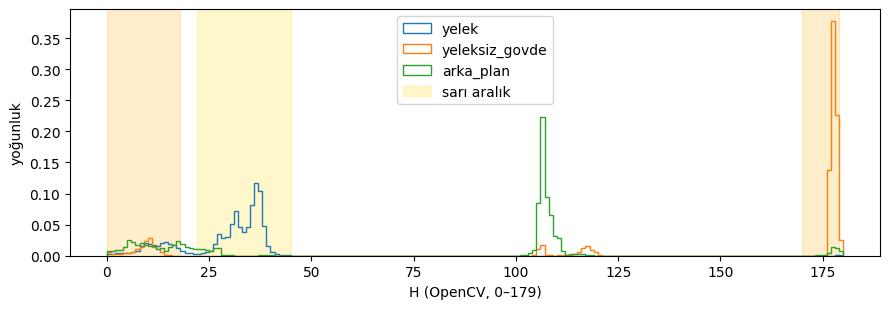

In [16]:
import color
stats, hists = color.hsv_stats(DEV_IDS, gt)
display(stats.round(0))
color.plot_hue(hists, P, path=RES / 'fig' / 'hue_dev.png');

## 5a — İki HSV aralığını belirle (sarı/sarı-yeşil, turuncu-kırmızı)
H 0–179; turuncu-kırmızı 0'ın iki yanına düşebilir (iki aralık). Ödev 1 bulgularını kullanın. Yalnız `P` sözlüğünü değiştirip aşağıdaki hücreyle bakın.

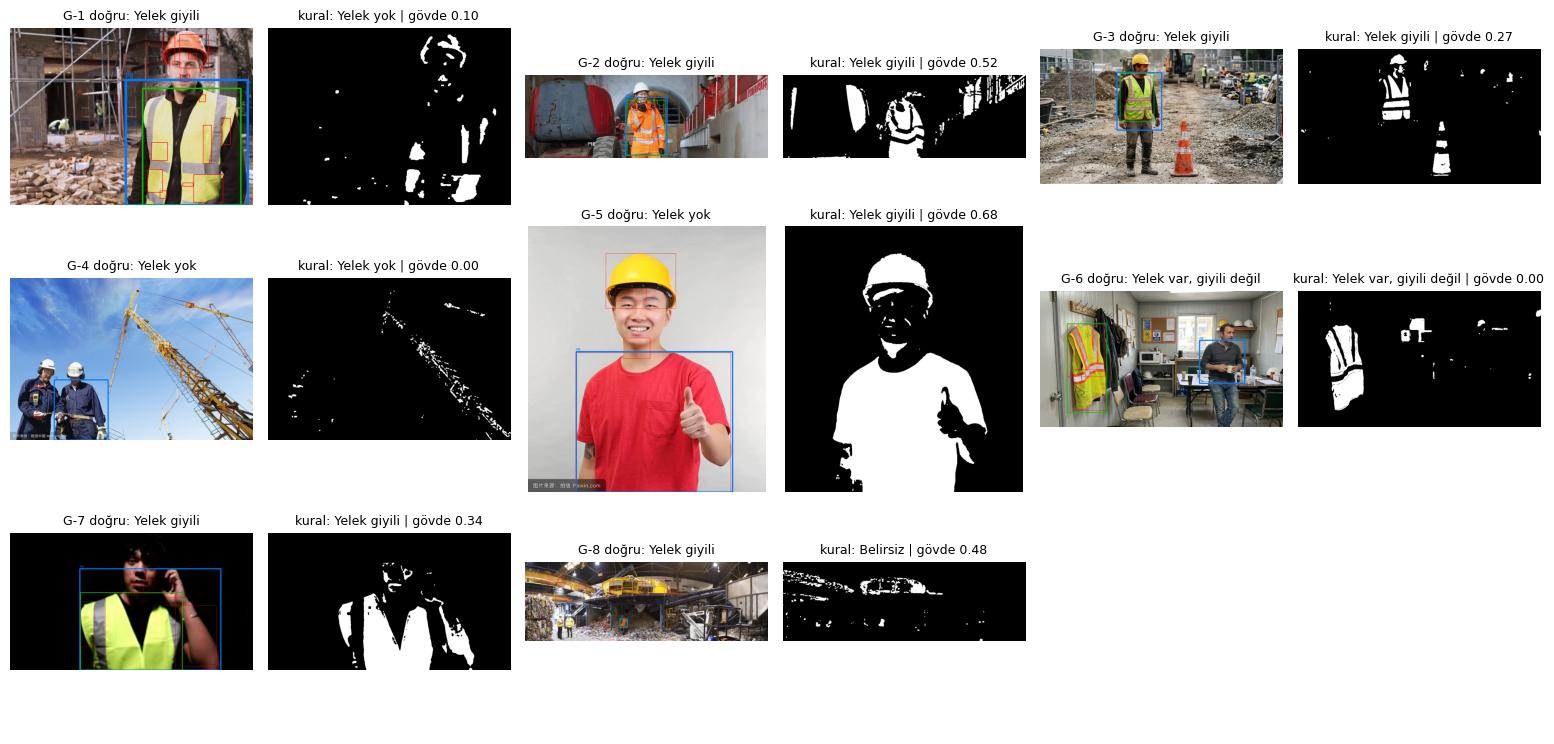

In [17]:
P['hsv_yellow'] = [[22, 100, 100], [45, 255, 255]]
P['hsv_orange'] = [[[0, 120, 100], [18, 255, 255]], [[170, 120, 100], [179, 255, 255]]]
P['pre_filter'] = {'name': 'median', 'k': 5}        # 5b: none / gauss / median / bilateral
P['min_part_area_pct'] = 0.05                        # 5d: görüntü alanının yüzdesi
color.show_masks(DEV_IDS, gt, P, path=RES / 'fig' / 'masks_dev.png');

In [18]:
dev = color.run(DEV_IDS, gt, P, tag='color_dev')
display(dev[['id', 'dogru_sinif', 'kural_sinifi', 'govde_maske_orani', 'maske_alan_orani', 'parca_sayisi', 'tp', 'fp', 'fn', 'gerekce']])
color.summary(dev);

,id,dogru_sinif,kural_sinifi,govde_maske_orani,maske_alan_orani,parca_sayisi,tp,fp,fn,gerekce
0,G-1,Yelek giyili,Yelek yok,0.097287,0.044767,12,0,12,1,iv: hiçbiri
1,G-2,Yelek giyili,Yelek giyili,0.517797,0.148962,25,1,24,0,ii: gövde maske oranı 0.518 >= 0.15
2,G-3,Yelek giyili,Yelek giyili,0.274442,0.042066,13,0,13,1,ii: gövde maske oranı 0.274 >= 0.15
3,G-4,Yelek yok,Yelek yok,0.002099,0.015206,4,0,4,0,iv: hiçbiri
4,G-5,Yelek yok,Yelek giyili,0.681007,0.266256,4,0,4,0,ii: gövde maske oranı 0.681 >= 0.15
5,G-6,"Yelek var, giyili değil","Yelek var, giyili değil",0.000926,0.069565,7,1,6,0,iii: gövdesiz en büyük parça 17984px > 0.2×34571
6,G-7,Yelek giyili,Yelek giyili,0.342103,0.147210,10,1,9,0,ii: gövde maske oranı 0.342 >= 0.15
7,G-8,Yelek giyili,Belirsiz,0.479391,0.042575,14,1,13,0,i: gövde yüksekliği 36px < 40


Doğru sınıf: 5/8 | TP/FP/FN (8 görüntü): 4/85/2


## Dondurma 2
Gerekçeleri doldurun (`filtre_gerekcesi`, `min_part_area_gerekcesi`, `hsv_durumu`), C'nin `template.cut_xy` ve D'nin açı/ölçek
seçimi de params.json'a yazılmış olsun; sonra kaydedip dondurun. Bundan sonra eşik değişmez (5e).

In [19]:
P['hsv_durumu'] = 'DENEME — başlangıç aralıkları, B henüz belirlemedi'
P['filtre_gerekcesi'] = 'DENEME'
P['min_part_area_gerekcesi'] = 'DENEME'
save_params(P); freeze_params()

params.json zaten dondurulmuş: 2026-11-10T21:09:21


{'_frozen': True,
 '_frozen_at': '2026-11-10T21:09:21',
 '_aciklama': "Dondurma 2: B, aşağıdaki HSV aralıklarını, filtreyi ve parça alanı eşiğini YALNIZ G-1…G-8 üzerinde belirler, common.freeze_params() çağırır; params.json'un o anki kopyası ve SHA-256 özeti otomatik olarak kayitlar/ klasörüne yazılır (commit yerine). Bundan sonra hiçbir değer değişmez (5e); sonradan yapılan her deneme 'sonraki kontrol' satırı olur (9b).",
 'hsv_durumu': 'DENEME — başlangıç aralıkları, B henüz belirlemedi',
 'hsv_yellow': [[22, 100, 100], [45, 255, 255]],
 'hsv_orange': [[[0, 120, 100], [18, 255, 255]],
  [[170, 120, 100], [179, 255, 255]]],
 'pre_filter': {'name': 'median', 'k': 5},
 'filtre_gerekcesi': 'DENEME',
 'open_kernel': 3,
 'min_part_area_pct': 0.05,
 'ratio_after_parts': False,
 '_ratio_after_parts': "false: maske ve gövde maske oranı 3x3 açmadan sonraki maskeden (5c). true: 5d'de küçük parçalar atıldıktan sonraki maskeden. Seçim dondurulur.",
 'min_part_area_gerekcesi': 'DENEME',
 'rule': {

## 5c–5g — 12 kontrol görüntüsü (dondurmadan sonra)

In [20]:
P = load_params()
ctrl = color.run(CTRL_IDS, gt, P)
display(ctrl[['id', 'dogru_sinif', 'kural_sinifi', 'maske_alan_orani', 'govde_maske_orani', 'tp', 'fp', 'fn', 'tpfpfn_sayima_dahil', 'gerekce']])
color.summary(ctrl)
color.confusion(ctrl)

,id,dogru_sinif,kural_sinifi,maske_alan_orani,govde_maske_orani,tp,fp,fn,tpfpfn_sayima_dahil,gerekce
0,K-1,Yelek giyili,Yelek giyili,0.048094,0.366975,1,15,0,True,ii: gövde maske oranı 0.367 >= 0.15
1,K-2,Yelek giyili,Yelek giyili,0.199243,0.508691,1,5,0,True,ii: gövde maske oranı 0.509 >= 0.15
2,K-3,Yelek giyili,Yelek yok,0.048538,0.067609,0,10,1,True,iv: hiçbiri
3,K-4,Yelek giyili,Yelek giyili,0.004918,0.356499,1,0,0,True,ii: gövde maske oranı 0.356 >= 0.15
4,K-5,Yelek yok,Yelek yok,0.026319,0.085935,0,13,0,True,iv: hiçbiri
5,K-6,Yelek giyili,Yelek giyili,0.053425,0.196151,0,7,1,True,ii: gövde maske oranı 0.196 >= 0.15
6,K-7,Yelek yok,Yelek giyili,0.108217,0.296814,0,8,0,True,ii: gövde maske oranı 0.297 >= 0.15
7,K-8,Yelek yok,Yelek yok,0.035600,0.017353,0,3,0,True,iv: hiçbiri
8,K-9,"Yelek var, giyili değil","Yelek var, giyili değil",0.067837,0.024602,0,10,1,True,iii: gövdesiz en büyük parça 11542px > 0.2×51541
9,K-10,"Yelek var, giyili değil",Yelek yok,0.040488,0.124612,1,9,0,True,iv: hiçbiri


Doğru sınıf: 8/12 | TP/FP/FN (12 görüntü): 4/92/4


kural,Yelek giyili,"Yelek var, giyili değil",Yelek yok,Belirsiz
doğru,,,,
Yelek giyili,4,0,2,0
"Yelek var, giyili değil",0,1,1,0
Yelek yok,1,0,3,0
Belirsiz,0,0,0,0


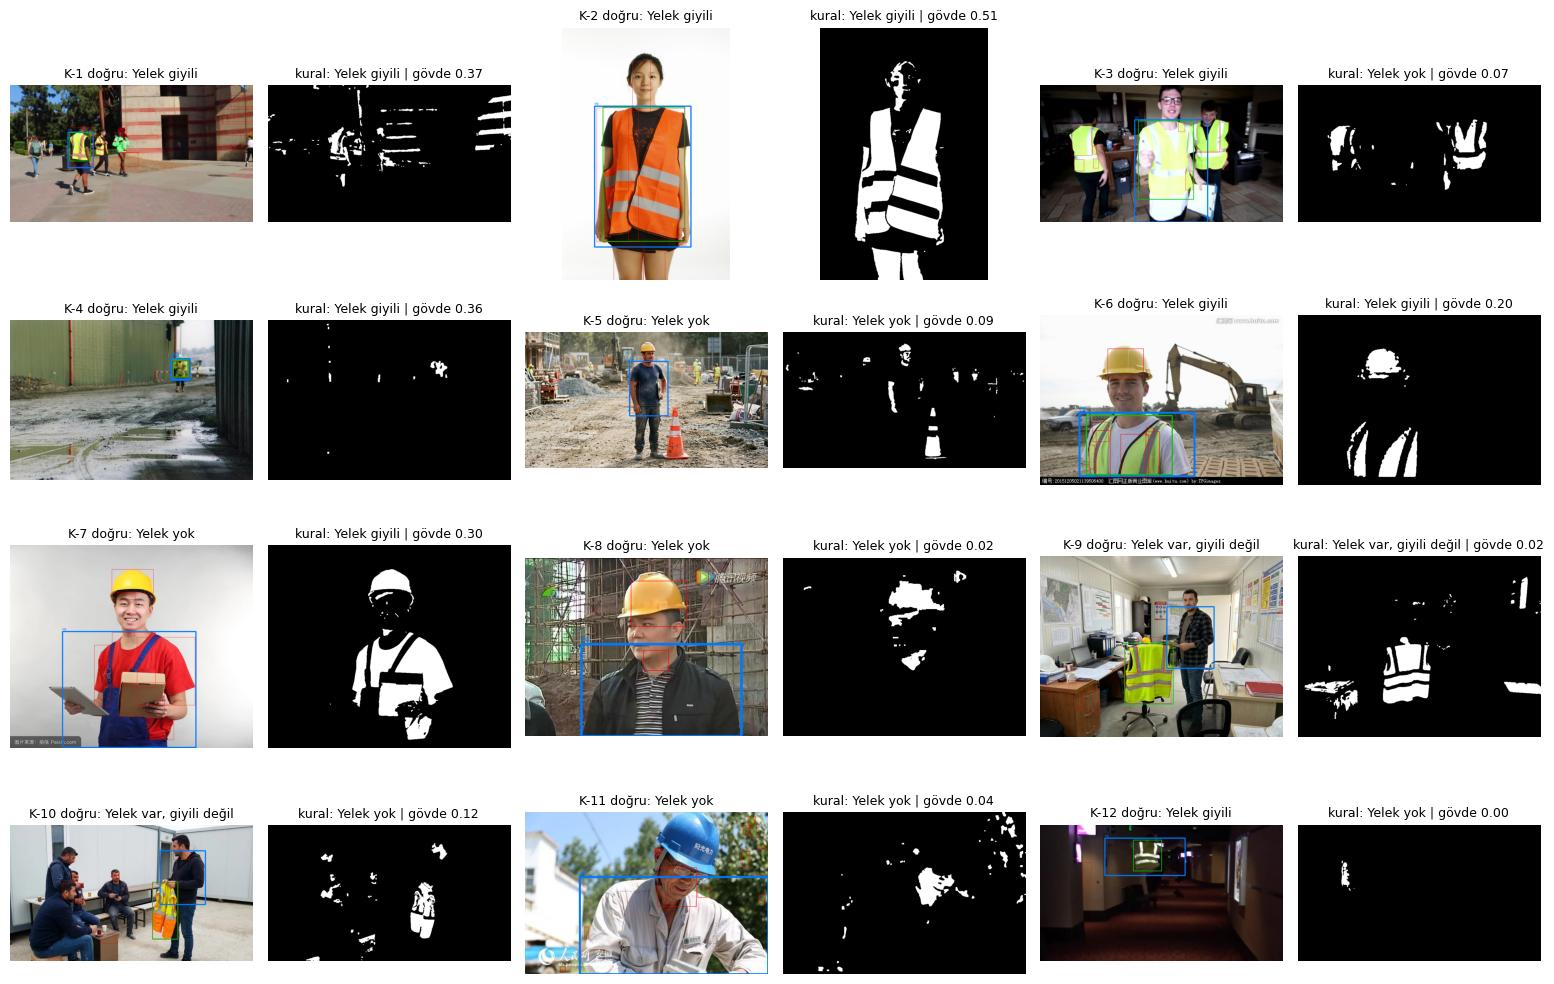

In [21]:
color.show_masks(CTRL_IDS, gt, P, path=RES / 'fig' / 'masks_control.png');

**H1 / S1:** yelek renginde nesne içeren görüntülerin (koni, forklift, sarı baret) maskesini ve FP'sini slayta koyun: "renk ≠ yelek".

## D2 — Filtre türü (yalnız filtre değişir)

filtre,bilateral,gauss(k=5),median(k=5),none
id,,,,
K-1,0.363,0.365,0.367,0.354
K-10,0.123,0.124,0.125,0.121
K-11,0.043,0.044,0.045,0.043
K-12,0.000,0.000,0.000,0.000
K-2,0.505,0.510,0.509,0.506
K-3,0.067,0.068,0.068,0.067
K-4,0.362,0.355,0.356,0.292
K-5,0.085,0.080,0.086,0.075
K-6,0.188,0.186,0.196,0.185


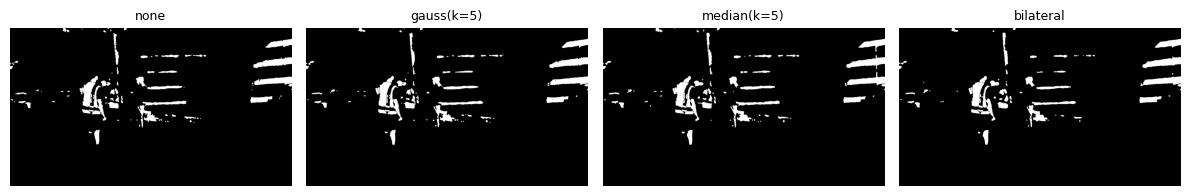

In [22]:
import experiments
d2 = experiments.d2(CTRL_IDS, gt, P, kisi='B', show_id='K-1')
d2.pivot_table(index='id', columns='filtre', values='govde_maske_orani').round(3)

In [23]:
d2.groupby('filtre')[['govde_maske_orani', 'maske_alan_orani', 'parca_sayisi', 'dogru_mu', 'fp']].mean().round(3)

,govde_maske_orani,maske_alan_orani,parca_sayisi,dogru_mu,fp
filtre,,,,,
bilateral,0.173,0.055,8.083,0.667,7.750
gauss(k=5),0.173,0.056,8.083,0.667,7.750
median(k=5),0.174,0.056,8.000,0.667,7.667
none,0.165,0.054,8.667,0.667,8.333
